# Image Acquisition

Acquire a full-frame image, a cropped rectangle scan, and images from multiple detectors.


### Run the servers

Make sure you are on the VPN and the AutoScript server is running. Then start the asyncroscopy Tango servers from the repository root:

```bash
uv run startup_scripts/run_servers.py
```


### Imports


In [1]:
import os
import json
import tango
import numpy as np
from pprint import pprint
import matplotlib.pyplot as plt
from tiled.client import from_uri

%matplotlib ipympl

### Ping servers


In [2]:
DB_HOST = "10.46.217.241"
# DB_HOST = "localhost"
DB_PORT = 9094

os.environ["TANGO_HOST"] = f"{DB_HOST}:{DB_PORT}"

server_names = ['stage', 'scan', 'eds', 'camera', 'data', 'instrument']

scan = tango.DeviceProxy("asyncroscopy/scan/default")
camera = tango.DeviceProxy("asyncroscopy/camera/default")
stage = tango.DeviceProxy("asyncroscopy/stage/default")
microscope = tango.DeviceProxy("asyncroscopy/instrument/default")
data = tango.DeviceProxy("asyncroscopy/data/default")

for proxy in [scan, microscope, data]:
    print(proxy)
    proxy.set_timeout_millis(120_000)
    proxy.ping()
    print(proxy.name(), proxy.state())


SCAN(asyncroscopy/scan/default)
asyncroscopy/scan/default ON
AutoScriptMicroscope(asyncroscopy/instrument/default)
asyncroscopy/instrument/default ON
DATA(asyncroscopy/data/default)
asyncroscopy/data/default ON


In [3]:
import json
microscope.get_command_list()
microscope.unblank_beam()

### Set Tiled Client


In [4]:
config = json.loads(data.get_config())
client = from_uri(config.get("uri"))
print("Tiled keys:", list(client))

Tiled keys: ['stem_image_HAADF_20261028T094156007899.h5', 'stem_image_HAADF_20261028T094637937677.h5', 'stem_image_HAADF_20261028T094711141038.h5', 'stem_image_HAADF_20261028T094758485038.h5', 'stem_image_HAADF_20261028T095122778622.h5', 'stem_image_HAADF_20261102T074536669426.h5', 'stem_image_HAADF_20261102T074542028856.h5', 'stem_image_HAADF_20261102T074545061245.h5', 'stem_image_HAADF_20261102T074548179323.h5', 'stem_image_HAADF_20261102T074551518751.h5', 'stem_image_HAADF_20261102T074554925878.h5', 'stem_image_HAADF_20261102T074558123636.h5', 'stem_image_HAADF_20261102T074601279587.h5', 'stem_image_HAADF_20261102T074604291380.h5', 'stem_image_HAADF_20261102T074607345704.h5', 'stem_image_HAADF_20261102T074610330067.h5', 'stem_image_HAADF_20261102T074613292259.h5', 'stem_image_HAADF_20261102T074616368283.h5', 'stem_image_HAADF_20261102T074619448791.h5', 'stem_image_HAADF_20261102T074805022894.h5', 'stem_image_HAADF_20261102T074807441747.h5', 'stem_image_HAADF_20261102T074810219596.h5

In [5]:
client = from_uri(config.get("uri"))
print("Tiled keys:", list(client))

Tiled keys: ['stem_image_HAADF_20261028T094156007899.h5', 'stem_image_HAADF_20261028T094637937677.h5', 'stem_image_HAADF_20261028T094711141038.h5', 'stem_image_HAADF_20261028T094758485038.h5', 'stem_image_HAADF_20261028T095122778622.h5', 'stem_image_HAADF_20261102T074536669426.h5', 'stem_image_HAADF_20261102T074542028856.h5', 'stem_image_HAADF_20261102T074545061245.h5', 'stem_image_HAADF_20261102T074548179323.h5', 'stem_image_HAADF_20261102T074551518751.h5', 'stem_image_HAADF_20261102T074554925878.h5', 'stem_image_HAADF_20261102T074558123636.h5', 'stem_image_HAADF_20261102T074601279587.h5', 'stem_image_HAADF_20261102T074604291380.h5', 'stem_image_HAADF_20261102T074607345704.h5', 'stem_image_HAADF_20261102T074610330067.h5', 'stem_image_HAADF_20261102T074613292259.h5', 'stem_image_HAADF_20261102T074616368283.h5', 'stem_image_HAADF_20261102T074619448791.h5', 'stem_image_HAADF_20261102T074805022894.h5', 'stem_image_HAADF_20261102T074807441747.h5', 'stem_image_HAADF_20261102T074810219596.h5

### Configure scan


In [6]:
scan.dwell_time = 1e-6
scan.imsize = 512
scan.scan_region = [0, 0, 1, 1]
scan.output_format = ".h5"

print("dwell_time :", scan.dwell_time)
print("image size :", scan.imsize)
print("scan region:", list(scan.scan_region))


dwell_time : 1e-06
image size : 512
scan region: [np.float64(0.0), np.float64(0.0), np.float64(1.0), np.float64(1.0)]


In [7]:
microscope.set_column_valves('open')

In [8]:
json.loads(microscope.get_parameters())

{'system': 'Titan',
 'vacuum': 'Ready',
 'column_valves': 'Opened',
 'is_accelerator_on': True,
 'acceleration_voltage': 200000.0,
 'optical_mode': 'Stem',
 'illumination_mode': 'Probe',
 'objective_lens_mode': 'HM',
 'projector_mode': 'Diffraction',
 'spot_size': 7,
 'beam_stopper': 'Retracted',
 'beam_blanker': False,
 'is_eftem_on': False,
 'scan_rotation': 0.0,
 'scan_field_of_view': 5.000000058430487e-08,
 'C1': '2000',
 'C2': '70',
 'C3': '2000',
 'Objective': 'Retracted',
 'SA': 'Retracted',
 'GunTilt': [0.00168000000000119, 0.157782200000001],
 'GunShift': [0.0143537281127564, 0.0109430348808915],
 'BeamTilt': [0.0, 0.0],
 'BeamShift': [0.0, 0.0],
 'ImageTilt': [0.0, 0.0],
 'ImageShift': [0.0, 0.0]}

In [11]:
print(f"Current stage.z: {float(stage.z) * 1e6:+.6f} µm")

Current stage.z: -0.001770 µm


### Acquire a HAADF image


In [17]:
stage.z = 0e-6 +0e-6
def contrast(image):
    image = np.asarray(image, dtype=np.float64)
    low, high = np.percentile(image, [1, 99])
    clipped = np.clip(image, low, high)
    return float(np.std(clipped) / (abs(np.mean(clipped)) + 1e-12))

CommunicationFailed: DevFailed[
    DevError[
        desc = TRANSIENT CORBA system exception: TRANSIENT_CallTimedout
        origin = DeviceProxy:write_attribute()
        reason = API_CorbaException
        severity = ERR
    ],
    DevError[
        desc = Timeout (3000 mS) exceeded on device asyncroscopy/stage/default
        origin = DeviceProxy:write_attribute()
        reason = API_DeviceTimedOut
        severity = ERR
    ]
]

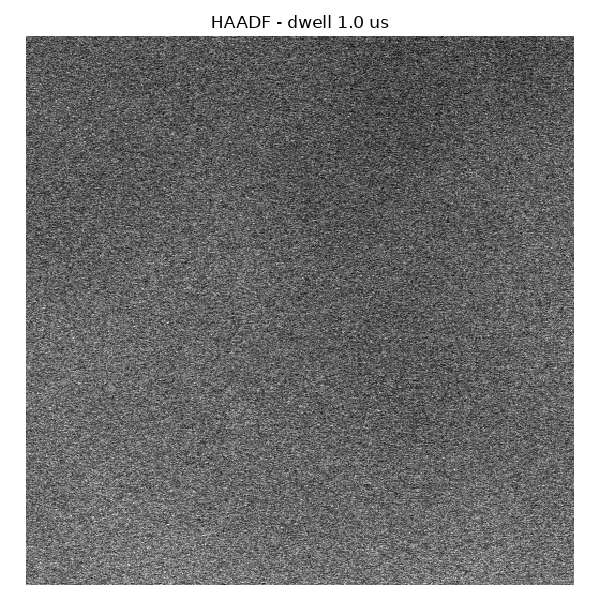

In [18]:
microscope.set_fov(5000*1e-9)
microscope.set_image_shift([0e-9, 0])
data_key = microscope.acquire_scanned_image(["haadf"])

image = client[data_key]["image"]["HAADF"].read()

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray", interpolation="none")
ax.set_title(f"HAADF - dwell {scan.dwell_time * 1e6:.1f} us")
ax.axis("off")
plt.tight_layout()

In [23]:
#stage.z  = -90e-6
stage_value = []
contrast = []
for i in range(20):
    
    print(stage.z*1e6)
    stage.z -= 10e-6
    stage_value.append(stage.z)

    data_key = microscope.acquire_scanned_image(["haadf"])
    image = client[data_key]["image"]["HAADF"].read()
    contrast.append(np.std(image) / (abs(np.mean(image) + 1e-12)))
    metadata = dict(client[data_key]["image"]["HAADF"].metadata)
    print(f"{stage.z*1e6:.2f} Contrast: {np.std(image) / (abs(np.mean(image) + 1e-12)):.4f}")
    
data_key

-0.00177000000003702


KeyboardInterrupt: 

In [19]:
stage_value = []
contrast = [0,0]
for i in range(20):
    
    print(stage.z*1e6)
    stage.z -= 10e-6
    stage_value.append(stage.z)

    data_key = microscope.acquire_scanned_image(["haadf"])
    image = client[data_key]["image"]["HAADF"].read()
    contrast.append(np.std(image) / (abs(np.mean(image) + 1e-12)))
    print(f"z-height: {stage.z*1e6:.2f}mum -  Contrast: {np.std(image) / (abs(np.mean(image) + 1e-12)):.4f}")
    if contrast[-1] < contrast[-2]:
        print("Contrast decreased, stopping scan.")
        break
    
contrast = [0,0]
for i in range(20):
    print(stage.z*1e6)
    stage.z += 1e-6
    stage_value.append(stage.z)

    data_key = microscope.acquire_scanned_image(["haadf"])
    image = client[data_key]["image"]["HAADF"].read()
    contrast.append(np.abs(np.std(image) / (abs(np.mean(image) + 1e-12))))
    print(f"z-height: {stage.z*1e6:.2f}mum -  Contrast: {np.std(image) / (abs(np.mean(image) + 1e-12)):.4f}")
    if contrast[-1] < contrast[-2]:
        print("Contrast decreased, stopping scan.")
        break

stage.z += .3e-6
stage.z -= .3e-6

contrast = [0,0]
for i in range(50):
    stage.z -= .1e-6
    stage_value.append(stage.z)

    data_key = microscope.acquire_scanned_image(["haadf"])
    image = client[data_key]["image"]["HAADF"].read()
    contrast.append(np.abs(np.std(image) / (abs(np.mean(image) + 1e-12))))

    print(f"z-height: {stage.z*1e6:.2f}mum -  Contrast: {np.std(image) / (abs(np.mean(image) + 1e-12)):.4f}")
    if contrast[-1] < contrast[-2]:
        print("Contrast decreased, stopping scan.")
        break
    
stage.z -= .2e-6
stage.z += .3e-6

-0.00177000000003702
z-height: -10.00mum -  Contrast: 0.1847
-10.004460000000037
z-height: -20.01mum -  Contrast: 0.1854
-20.00715000000004
z-height: -30.01mum -  Contrast: 0.1886
-30.00984000000004
z-height: -40.01mum -  Contrast: 0.1959
-40.01253000000004
z-height: -50.02mum -  Contrast: 0.2087
-50.015220000000035
z-height: -60.02mum -  Contrast: 0.2270
-60.017910000000036
z-height: -70.02mum -  Contrast: 0.2471
-70.02060000000004
z-height: -80.02mum -  Contrast: 0.2821
-80.01630000000003
z-height: -90.02mum -  Contrast: 0.3559
-90.01899000000003
z-height: -100.02mum -  Contrast: 0.4973
-100.02168000000005
z-height: -110.02mum -  Contrast: 0.8151
-110.02437000000005
z-height: -120.03mum -  Contrast: 0.6051
Contrast decreased, stopping scan.
-120.02706000000003
z-height: -119.03mum -  Contrast: 0.6188
-119.02749000000003
z-height: -118.03mum -  Contrast: 0.6394
-118.02792000000004
z-height: -117.03mum -  Contrast: 0.6649
-117.02835000000005
z-height: -116.03mum -  Contrast: 0.6964
-11

In [ ]:
microscope.set_fov(500*1e-9)
stage_value = []
contrast = [0,0]
for i in range(20):
    
    print(stage.z*1e6)
    stage.z += .1e-6
    stage_value.append(stage.z)

    data_key = microscope.acquire_scanned_image(["haadf"])
    image = client[data_key]["image"]["HAADF"].read()
    contrast.append(np.std(image) / (abs(np.mean(image) + 1e-12)))
    print(f"{stage.z*1e6:.2f} Contrast: {np.std(image) / (abs(np.mean(image) + 1e-12)):.4f}")
    if contrast[-1] < contrast[-2]:
        print("Contrast decreased, stopping scan.")
        break
stage.z += .2e-6
stage.z -= .2e-6

contrast = [0,0]
for i in range(20):
    print(stage.z*1e6)
    stage.z -= .01e-6
    stage_value.append(stage.z)

    data_key = microscope.acquire_scanned_image(["haadf"])
    image = client[data_key]["image"]["HAADF"].read()
    contrast.append(np.abs(np.std(image) / (abs(np.mean(image) + 1e-12))))
    print(f"{stage.z*1e6:.2f} Contrast: {np.std(image) / (abs(np.mean(image) + 1e-12)):.4f}")
    if contrast[-1] < contrast[-2]:
        print("Contrast decreased, stopping scan.")
        break





-112.19127000000005
-112.09 Contrast: 1.1225
-112.09341000000003
-112.00 Contrast: 1.1625
-111.99555000000004
-111.90 Contrast: 1.2029
-111.89769000000004
-111.80 Contrast: 1.2304
-111.79983000000004
-111.70 Contrast: 1.2351
-111.70197000000003
-111.60 Contrast: 1.2168
Contrast decreased, stopping scan.
-111.60411000000003
-111.59 Contrast: 1.2142
-111.59013000000004
-111.58 Contrast: 1.2113
Contrast decreased, stopping scan.


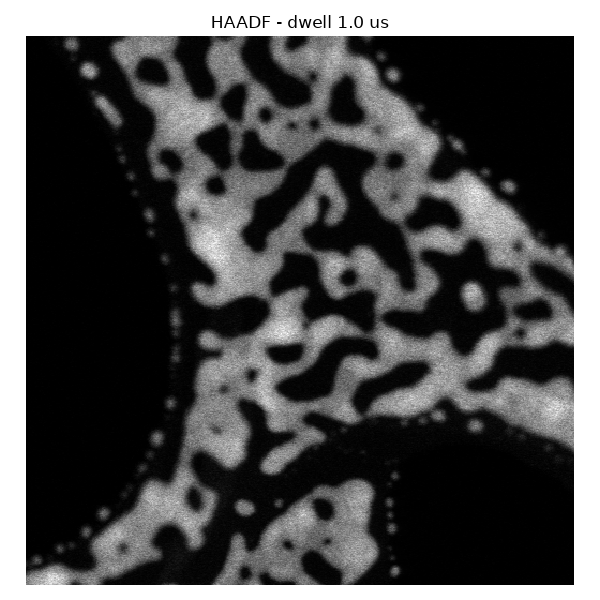

In [22]:
microscope.set_fov(500*1e-9)
microscope.set_image_shift([0e-9, 0])
data_key = microscope.acquire_scanned_image(["haadf"])

image = client[data_key]["image"]["HAADF"].read()
metadata = dict(client[data_key]["image"]["HAADF"].metadata)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray", interpolation="none")
ax.set_title(f"HAADF - dwell {scan.dwell_time * 1e6:.1f} us")
ax.axis("off")
plt.tight_layout()

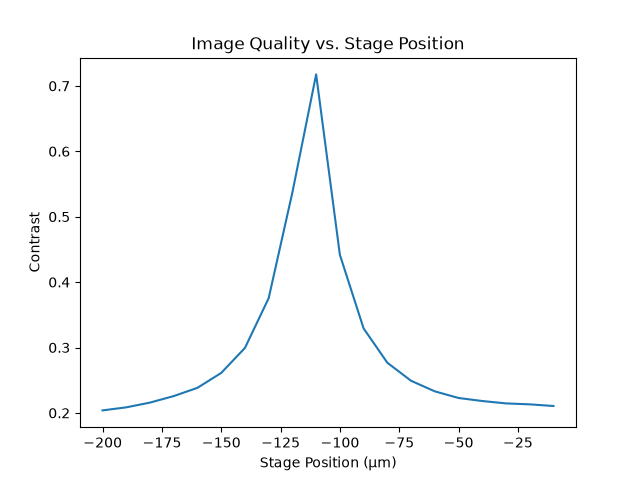

In [29]:
plt.figure()
plt.plot(np.array(stage_value)*1e6, contrast)
plt.xlabel("Stage Position (μm)")
plt.ylabel("Contrast")
plt.title("Image Quality vs. Stage Position")
plt.show()

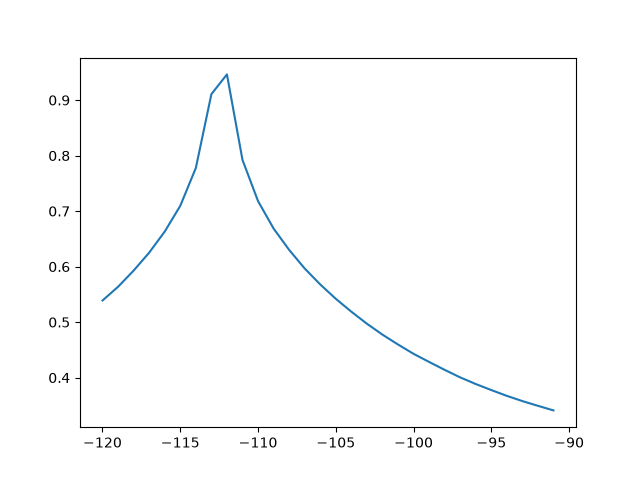

In [24]:
plt.figure()
plt.plot(np.array(stage_value)*1e6, contrast)

In [7]:
print("Metadata:")
pprint(metadata)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)


Metadata:
{'acquisition_type': 'stem_image', 'detector': 'HAADF'}
Image shape: (512, 512)
Image dtype: float32


### Acquire multiple detectors


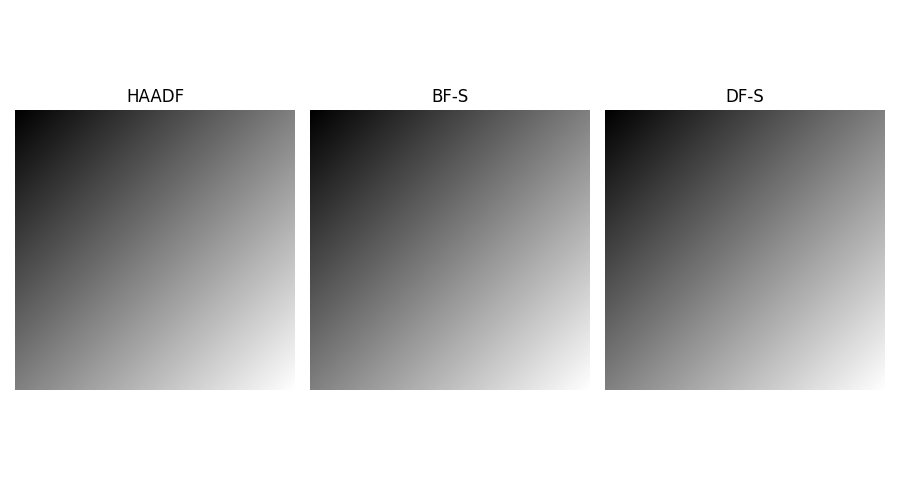

In [9]:
scan.dwell_time = 1e-6
scan.imsize = 512
scan.scan_region = [0, 0, 1, 1]
detector_list = ["HAADF", "BF-S", "DF-S"]
key = microscope.acquire_scanned_image(["HAADF", "BF-S", "DF-S"])
dset = client[key]["image"]

images = []
names = []
for detector_name in dset:
    image = dset[detector_name].read()
    images.append(image)
    names.append(detector_name)

fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 5))
for ax, im, n in zip(axes, images, names):
    ax.imshow(im, cmap="gray")
    ax.set_title(str(n).upper())
    ax.axis("off")
fig.tight_layout()


## if using tiff as output fomrat(AutoScript Native) i.e scan.output_format = ".tiff"

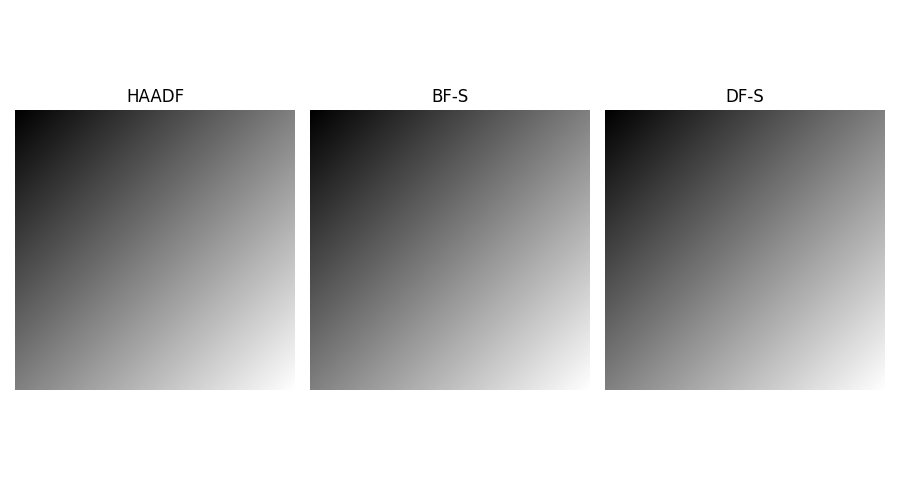

In [10]:
scan.dwell_time = 1e-6
scan.imsize = 512
scan.scan_region = [0, 0, 1, 1]
scan.output_format = ".tiff"

detector_list = ["HAADF", "BF-S", "DF-S"]
key = microscope.acquire_scanned_image(detector_list)   # returns the shared stem, e.g. "stem_image_20260604T123909936109"

images = []
names = []
for det in detector_list:
    node = client[f"{key}_{det.upper()}.tiff"]   # one TIFF per detector
    images.append(node.read())                   # read the image array directly
    names.append(det)

fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 5))
for ax, im, n in zip(axes, images, names):
    ax.imshow(im, cmap="gray")
    ax.set_title(str(n).upper())
    ax.axis("off")
fig.tight_layout()

### Acquire a cropped rectangle scan


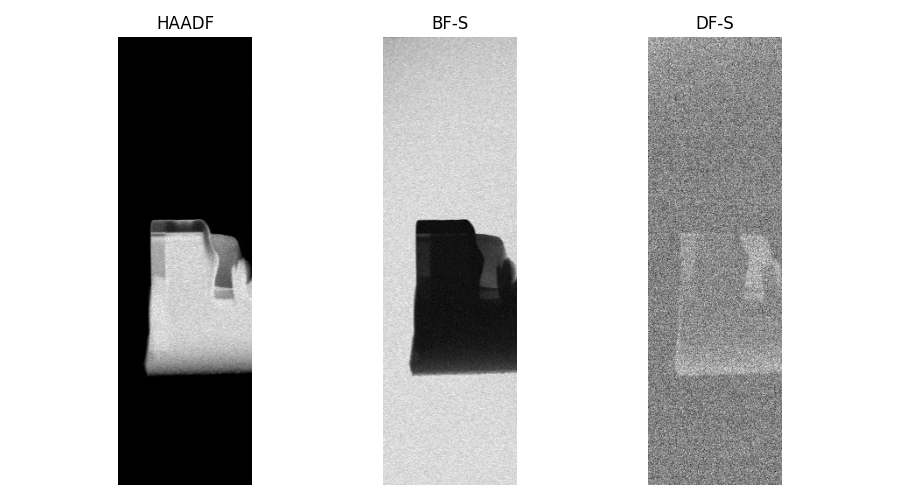

In [9]:
scan.dwell_time = 1e-6
scan.imsize = 512
scan.output_format = ".tiff"
scan.scan_region = [0, 0, .3, 1]


detector_list = ["HAADF", "BF-S", "DF-S"]
key = microscope.acquire_scanned_image(detector_list)   # returns the shared stem, e.g. "stem_image_20260604T123909936109"

images = []
names = []
for det in detector_list:
    node = client[f"{key}_{det.upper()}.tiff"]   # one TIFF per detector
    images.append(node.read())                   # read the image array directly
    names.append(det)

fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 5))
for ax, im, n in zip(axes, images, names):
    ax.imshow(im, cmap="gray")
    ax.set_title(str(n).upper())
    ax.axis("off")
fig.tight_layout()

## Lets do some acquisiton on the Camera now to get some diffraction patterns.
**Make sure to check the screen current(less than 100 pico Amps should be good)**

In [ ]:
camera.camera_detector = "BM-Ceta"  # use "Flucam" to acquire from Flucam
camera.imsize = 1024
camera.exposure_time = 0.5
camera.readout_area = "Half"
camera.frame_combining = 1
camera.output_format = ".h5"

camera_key = microscope.acquire_camera_image()
camera_node = client[camera_key]["image"]
camera_image = camera_node.read()
camera_metadata = dict(camera_node.metadata)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(camera_image, cmap="gray", interpolation="none")
ax.set_title(
    f"{camera.camera_detector} - exposure {camera.exposure_time:.3f} s"
)
ax.axis("off")
plt.tight_layout()

print("Camera key:", camera_key)
print("Image shape:", camera_image.shape)
pprint(camera_metadata)

### Optional: save the camera image as AutoScript-native TIFF


In [ ]:
camera.output_format = ".tiff"
camera_stem = microscope.acquire_camera_image()

camera_tiff_key = f"{camera_stem}_{camera.camera_detector}.tiff"
camera_tiff = client[camera_tiff_key].read()

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(camera_tiff, cmap="gray", interpolation="none")
ax.set_title(camera_tiff_key)
ax.axis("off")
plt.tight_layout()

# Restore the default for subsequent acquisitions.
camera.output_format = ".h5"